# Clustering with K-Means, EM and DBSCAN, and a comparison of the resulting clusters

## Aim
To perform clustering using **K-Means**, **EM** (Gaussian mixture) and **DBSCAN**, and to compare the clusters they produce.

This notebook shares its code (`data.py`, `clustering.py`, `metrics.py`, `benchmark.py`) with the interactive
Hugging Face Space, so the numbers here and in the app are the same numbers.

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.metrics import adjusted_rand_score as ari

from data import SHAPES, make_shape, NewsData
from clustering import (run_kmeans, run_gmm, run_dbscan, suggest_eps, k_distance, sweep_kmeans, sweep_gmm, NOISE)
from metrics import score_table, agreement_matrix, contingency, cluster_summary
from benchmark import _oracle_dbscan

# 4-colour categorical set validated for colour-vision deficiency (see viz.py); noise is grey.
PAL = ["#2a78d6", "#eda100", "#e87ba4", "#008300"]; MARK = ["o", "s", "D", "^"]
pd.set_option("display.width", 160, "display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def draw(ax, X, labels, title=""):
    """Scatter coloured by cluster id (first four clusters get palette colours, the rest grey; noise = x)."""
    ids = [c for c in np.unique(labels) if c != NOISE]
    ids.sort(key=lambda c: -np.sum(labels == c))
    for i, c in enumerate(ids):
        m = labels == c
        kw = dict(c=PAL[i], marker=MARK[i], s=14, alpha=.8, linewidths=0) if i < 4 else dict(facecolors="none", edgecolors="#898781", s=14)
        ax.scatter(X[m, 0], X[m, 1], **kw)
    if (labels == NOISE).any():
        ax.scatter(*X[labels == NOISE].T, c="#898781", marker="x", s=18, linewidths=1)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

## 2. Datasets
Two families, because one dataset rarely separates three algorithms:

* **Synthetic 2-D shapes** whose geometry exposes each algorithm's assumption (round, elliptical, non-convex, varied density).
* **Real text**: 3,000 AG News headlines (750 each of World, Sports, Business, Sci/Tech), embedded with
  `all-MiniLM-L6-v2` and reduced with UMAP (`precompute.py`). The topic labels are used **only** to score, never to cluster.

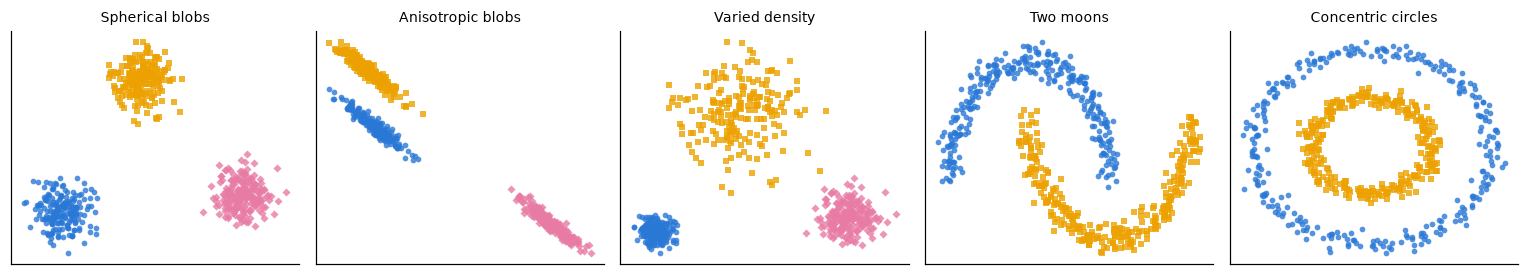

In [2]:
fig, axes = plt.subplots(1, 5, figsize=(14, 2.6))
for ax, (name, (label, blurb)) in zip(axes, SHAPES.items()):
    X, y = make_shape(name)
    draw(ax, X, y, label)
plt.tight_layout(); plt.show()

## 3. Procedure
| Algorithm | Idea | Key parameters | Assumes |
|---|---|---|---|
| **K-Means** | Alternate: assign each point to its nearest centroid, move centroids to the mean. Minimises within-cluster squared distance. | `k` | round, similar-size clusters |
| **EM (Gaussian mixture)** | Alternate: E-step computes each point's *probability* of belonging to each Gaussian, M-step re-fits means, covariances and weights. | components, covariance type | each cluster is a Gaussian (can be elliptical) |
| **DBSCAN** | Grow clusters from *core* points that have >= `min_samples` neighbours within `eps`; anything unreachable is **noise**. | `eps`, `min_samples` | clusters are dense regions separated by sparse ones; one global density |

Parameters are chosen two ways: **auto** (no labels: silhouette for `k`, BIC for EM, k-distance knee for `eps`) and
**oracle** (labels used to tune; an optimistic upper bound).

## 4. Results on the synthetic shapes (oracle-tuned parameters)

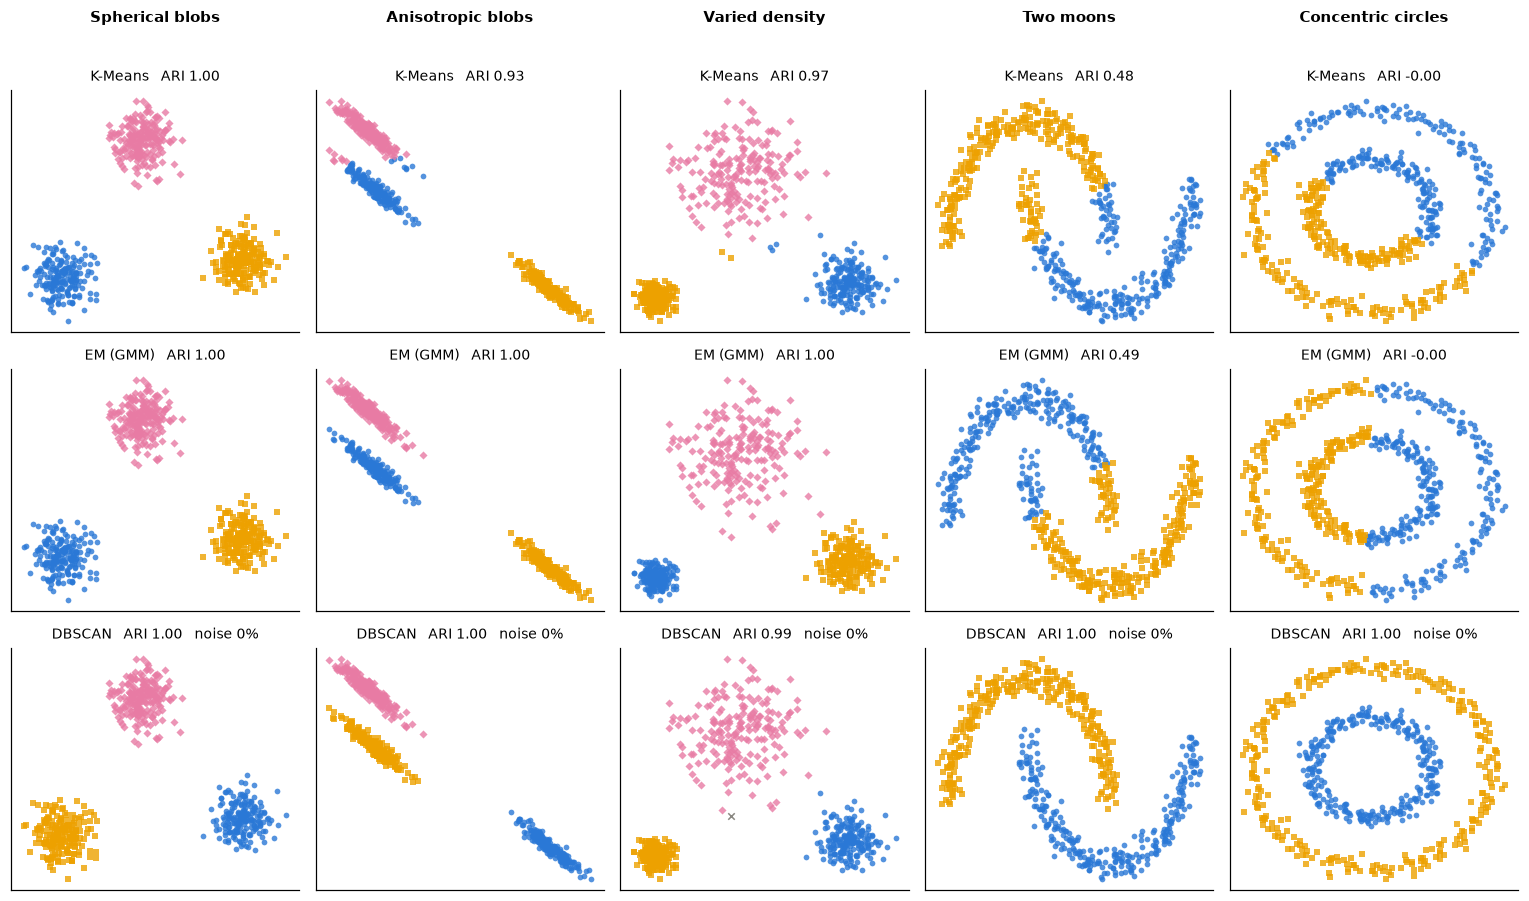

algorithm,DBSCAN,EM (GMM),K-Means
dataset,,,
Spherical blobs,1.000,1.000,1.000
Anisotropic blobs,1.000,1.000,0.928
Varied density,0.993,1.000,0.970
Two moons,1.000,0.494,0.480
Concentric circles,1.000,-0.001,-0.002


In [3]:
algos = ["K-Means", "EM (GMM)", "DBSCAN"]
fig, axes = plt.subplots(3, 5, figsize=(14, 8.2)); rows = []
for j, name in enumerate(SHAPES):
    X, y = make_shape(name); k = len(np.unique(y))
    eps, ms = _oracle_dbscan(X, y)
    for i, r in enumerate([run_kmeans(X, k), run_gmm(X, k, "full"), run_dbscan(X, eps, ms)]):
        a = ari(y, r.labels)
        draw(axes[i, j], X, r.labels, f"{r.name}   ARI {a:.2f}" + (f"   noise {r.noise_fraction:.0%}" if r.name == "DBSCAN" else ""))
        rows.append((SHAPES[name][0], r.name, a))
for j, name in enumerate(SHAPES): axes[0, j].annotate(SHAPES[name][0], (.5, 1.28), xycoords="axes fraction", ha="center", weight="bold")
plt.tight_layout(); plt.show()
pd.DataFrame(rows, columns=["dataset", "algorithm", "ARI"]).pivot(index="dataset", columns="algorithm", values="ARI").reindex([v[0] for v in SHAPES.values()]).round(3)

### Choosing the parameters without labels
For the **anisotropic** blobs: the elbow/silhouette curve for `k`, BIC/AIC for the number of Gaussian components, and the
k-distance plot for `eps`. Compare the silhouette's choice with the true `k = 3`.

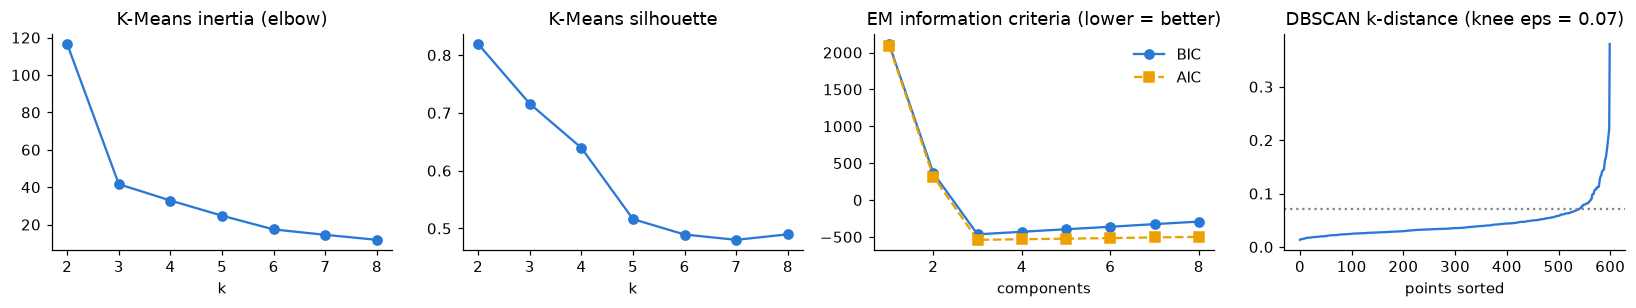

silhouette picks k = 2 | BIC picks 3 components | true k = 3


In [4]:
X, y = make_shape("aniso")
sk, sg = sweep_kmeans(X, range(2, 9)), sweep_gmm(X, range(1, 9))
d = k_distance(X, 5); eps = suggest_eps(X, 5)
fig, ax = plt.subplots(1, 4, figsize=(15, 2.9))
ax[0].plot(sk["k"], sk["inertia"], "o-", c=PAL[0]); ax[0].set(title="K-Means inertia (elbow)", xlabel="k")
ax[1].plot(sk["k"], sk["silhouette"], "o-", c=PAL[0]); ax[1].set(title="K-Means silhouette", xlabel="k")
ax[2].plot(sg["components"], sg["bic"], "o-", c=PAL[0], label="BIC"); ax[2].plot(sg["components"], sg["aic"], "s--", c=PAL[1], label="AIC")
ax[2].set(title="EM information criteria (lower = better)", xlabel="components"); ax[2].legend(frameon=False)
ax[3].plot(d, c=PAL[0]); ax[3].axhline(eps, c="#898781", ls=":"); ax[3].set(title=f"DBSCAN k-distance (knee eps = {eps:.2f})", xlabel="points sorted")
plt.tight_layout(); plt.show()
print("silhouette picks k =", sk["k"][int(np.nanargmax(sk["silhouette"]))], "| BIC picks", sg["components"][int(np.argmin(sg["bic"]))], "components | true k = 3")

## 5. Results on real data: news headlines
Clustering runs in UMAP 10-D; the 2-D map below is a UMAP projection used only for display.

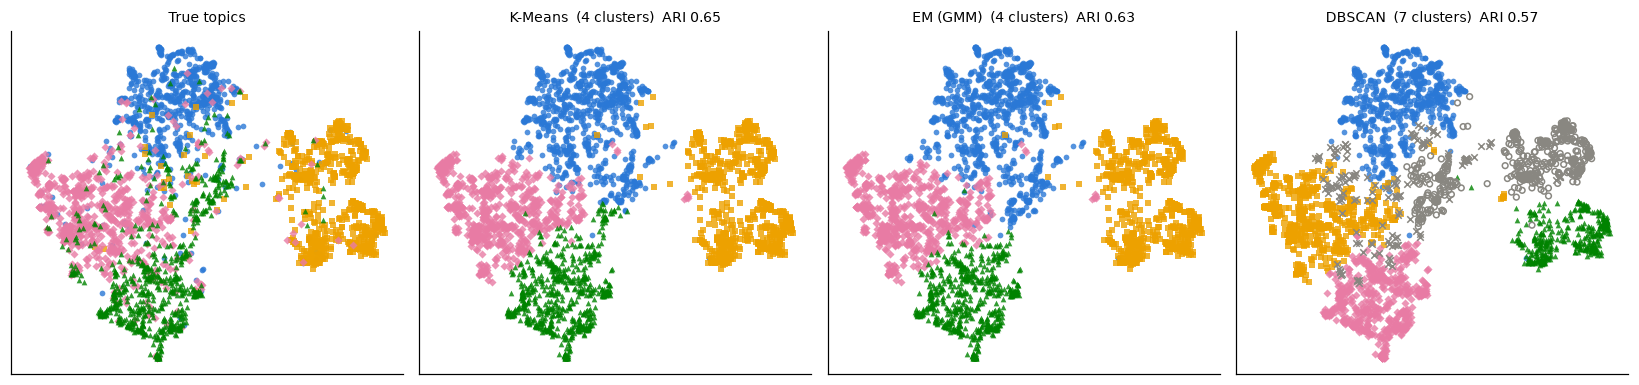

,params,clusters,noise_fraction,ARI,NMI,v_measure,silhouette,davies_bouldin,fit_ms
algorithm,,,,,,,,,
K-Means,k=4,4,0.000,0.652,0.623,0.623,0.546,0.703,16.8
EM (GMM),"components=4, covariance=full",4,0.000,0.630,0.607,0.607,0.542,0.696,38.7
DBSCAN,"eps=0.4723, min_samples=20",7,0.052,0.574,0.580,0.580,0.462,0.737,16.2


In [5]:
news = NewsData(); X10, X2, y, names = news.X_cluster, news.X_plot, news.y, news.label_names
eps, ms = suggest_eps(X10, 20), 20
res = [run_kmeans(X10, 4), run_gmm(X10, 4, "full"), run_dbscan(X10, _oracle_dbscan(X10, y)[0], _oracle_dbscan(X10, y)[1])]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
draw(axes[0], X2, y, "True topics")
for ax, r in zip(axes[1:], res): draw(ax, X2, r.labels, f"{r.name}  ({r.n_clusters} clusters)  ARI {ari(y, r.labels):.2f}")
plt.tight_layout(); plt.show()
score_table(X10, y, res)[["params", "clusters", "noise_fraction", "ARI", "NMI", "v_measure", "silhouette", "davies_bouldin", "fit_ms"]].round(3)

**Do the algorithms agree with each other?** (pairwise Adjusted Rand Index between their labelings)

In [6]:
agreement_matrix(res).round(3)

,K-Means,EM (GMM),DBSCAN
K-Means,1.000,0.942,0.755
EM (GMM),0.942,1.000,0.760
DBSCAN,0.755,0.760,1.000


**Where does each topic go?** (rows = true topic, columns = discovered cluster)

In [7]:
for r in res[:2]:
    print(r.name); display(contingency(y, r.labels, names))

K-Means


,C0,C1,C2,C3
World,14,28,681,27
Sports,3,718,18,11
Business,95,9,45,601
Sci/Tech,547,8,129,66


EM (GMM)


,C0,C1,C2,C3
World,28,26,683,13
Sports,718,12,17,3
Business,9,598,57,86
Sci/Tech,8,72,157,513


**What is inside the K-Means clusters?**

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
tv = TfidfVectorizer(stop_words="english", min_df=3, max_df=.5, sublinear_tf=True); T = tv.fit_transform(news.texts)
cluster_summary(X10, news.texts, res[0].labels, y, names, T, np.array(tv.get_feature_names_out()))

,cluster,size,majority class,purity,distinctive terms,most central headline
0,C2,873,World,78%,"iraq, president, afp, killed, minister, bush",Rumsfeld terms Ecuador ally in fighting terror...
1,C1,763,Sports,94%,"win, season, game, team, league, cup",Edelin Ruled Ineligible Syracuse point guard B...
2,C3,705,Business,85%,"oil, prices, percent, sales, quarter, profit",Lilly forecasting strong 2005 Eli Lilly and Co...
3,C0,659,Sci/Tech,83%,"microsoft, internet, software, service, ibm, m...",IDC Forum: Is IT creativity dead? Pouring fuel...


### The curse of dimensionality: the same algorithms in raw 384-D embedding space

In [9]:
raw = np.load("data/embeddings_384d.npy"); rows = []
for tag, X in (("UMAP 10-D", X10), ("raw 384-D", raw)):
    ms_ = 20; e = suggest_eps(X, ms_)
    for r in (run_kmeans(X, 4), run_gmm(X, 4, "full" if tag.startswith("UMAP") else "diag"), run_dbscan(X, e, ms_)):
        rows.append((tag, r.name, r.n_clusters, f"{r.noise_fraction:.1%}", round(ari(y, r.labels), 3)))
pd.DataFrame(rows, columns=["space", "algorithm", "clusters found", "noise", "ARI"])

,space,algorithm,clusters found,noise,ARI
0,UMAP 10-D,K-Means,4,0.0%,0.652
1,UMAP 10-D,EM (GMM),4,0.0%,0.630
2,UMAP 10-D,DBSCAN,6,2.3%,0.488
3,raw 384-D,K-Means,4,0.0%,0.576
4,raw 384-D,EM (GMM),4,0.0%,0.574
5,raw 384-D,DBSCAN,1,0.1%,0.000


## 6. Scorecard: every algorithm on every dataset

In [10]:
b = pd.read_csv("data/benchmark.csv"); order = [v[0] for v in SHAPES.values()] + ["News · UMAP 10-D", "News · raw 384-D"]
for proto, title in (("auto", "AUTO: no labels used to tune"), ("oracle", "ORACLE: labels used to tune (upper bound)")):
    print(title)
    display(b[b.protocol == proto].pivot(index="dataset", columns="algorithm", values="ARI").reindex(order).round(3))

AUTO: no labels used to tune


algorithm,DBSCAN,EM (GMM),K-Means
dataset,,,
Spherical blobs,0.939,1.000,1.000
Anisotropic blobs,0.936,1.000,0.571
Varied density,0.945,1.000,0.988
Two moons,0.933,0.251,0.349
Concentric circles,0.707,0.132,-0.002
News · UMAP 10-D,0.488,0.441,0.294
News · raw 384-D,0.000,0.360,0.539


ORACLE: labels used to tune (upper bound)


algorithm,DBSCAN,EM (GMM),K-Means
dataset,,,
Spherical blobs,1.000,1.000,1.000
Anisotropic blobs,0.999,1.000,0.947
Varied density,0.997,1.000,0.988
Two moons,0.999,0.500,0.482
Concentric circles,1.000,-0.002,-0.002
News · UMAP 10-D,0.574,0.630,0.652
News · raw 384-D,0.005,0.574,0.576


## 7. Comparison and conclusion

In [11]:
display(Markdown(open("findings.md").read()))

## Findings

*All numbers come from `benchmark.py` (shapes: mean of 5 random draws of 600 points; news: one fixed sample of 3,000 headlines). ARI = Adjusted Rand Index against the true labels. **Oracle** uses the labels to tune (an optimistic upper bound); **auto** uses none.*

**1. Each algorithm's assumption shows up exactly where theory says it should.**
- On round blobs all three score ARI ≈ 1.0.
- On stretched (anisotropic) blobs EM reaches 1.00 because it learns each cluster's covariance; K-Means, which assumes round clusters, reaches 0.95 even when given the correct *k*.
- On two moons and concentric circles **only DBSCAN works** (ARI 0.999 and 1.000 tuned). K-Means and EM score about 0.5 on moons and 0.00 on circles, because no centroid or Gaussian can separate a ring from the ring inside it.
- Varied density did **not** break anything at the contrast used here: all three scored ≥ 0.99 when tuned.

**2. Label-free quality metrics can prefer the wrong answer.** On concentric circles DBSCAN is perfect (ARI 1.00) yet has silhouette 0.11 and Davies-Bouldin 599, while K-Means is no better than chance (ARI −0.00) yet scores silhouette 0.35 and Davies-Bouldin 1.18. Silhouette, Davies-Bouldin and Calinski-Harabasz all reward compact, convex clusters, so they cannot judge DBSCAN fairly on ring-shaped data.

**3. Choosing the parameters mattered as much as choosing the algorithm.** Without labels, silhouette picked *k* = 2 on the anisotropic blobs (ARI 0.57 vs 0.95 at the true *k* = 3) and *k* = 2 on the news data (0.29 vs 0.65 at *k* = 4). BIC picked 8 components for EM on the news data (0.44 vs 0.63 at 4). On the news data the ranking even flips: tuned with labels, K-Means (0.65) > EM (0.63) > DBSCAN (0.57); tuned without labels, DBSCAN (0.49) > EM (0.44) > K-Means (0.29). A coarser 2-cluster split is not necessarily "wrong"; it just disagrees with a 4-topic labelling.

**4. High dimensions break DBSCAN, not K-Means or EM.** In raw 384-D embedding space DBSCAN returned one giant cluster for every `eps` tried (ARI 0.00), because distances between points concentrate and no density threshold separates anything. K-Means and EM still worked there (0.58 and 0.57) but trailed their UMAP 10-D scores (0.65 and 0.63). Reducing dimensionality first helped every algorithm. (The UMAP was fitted without labels; silhouette values are **not comparable** between the two spaces: 0.55 vs 0.04.)

**5. On real text no algorithm recovers the four topics cleanly.** The best ARI is 0.65. Sports (96% of its headlines in one K-Means cluster) and World (91%) separate well, but Sci/Tech (73%) and Business (80%) blur: 95 Business headlines landed in the Sci/Tech cluster and 129 Sci/Tech headlines landed with World (see the contingency heatmap in tab 2). Part of this is plausibly label ambiguity (tech-business stories fit both topics), though I did not test that. DBSCAN did not merge topics in UMAP space; it *fragmented* them into 6-7 clusters while labelling only 2-5% of points as noise.

**6. Stability and cost.** K-Means and EM were perfectly repeatable when the data matched their assumptions, but became seed-dependent when it did not (circles: stability 0.60 and 0.52). DBSCAN's stability of 1.0 only reflects that it is deterministic, not that it is right. EM was 1.5-10× slower than K-Means (typically 2-3×; it runs several initialisations). DBSCAN was faster than K-Means on all five 2-D datasets but about 1.3× slower on the 10-D news data. EM is the only one of the three that also gives soft assignments (a confidence per point).

**Caveats.** One news sample and one UMAP seed (no confidence intervals); five draws for the shapes; oracle numbers are optimistic by construction; all datasets are small, so timings are indicative only.

**When to use which (from this evidence).** K-Means: fast baseline when clusters are roughly round and *k* is known. EM: when clusters are elliptical or you need probabilities, and you can afford model selection with BIC. DBSCAN: when clusters have arbitrary shape and outliers matter, in **low-dimensional** data, with `eps` chosen carefully.


### Side-by-side summary
| | **K-Means** | **EM (GMM)** | **DBSCAN** |
|---|---|---|---|
| Cluster model | centroid, spherical | Gaussian, any covariance | density-connected region |
| Number of clusters | you choose `k` | you choose components (BIC helps) | found automatically (via `eps`, `min_samples`) |
| Assignment | hard | **soft** (probabilities) | hard, with explicit **noise** |
| Non-convex shapes | no | no | **yes** |
| Elliptical clusters | poor | **yes** | yes (if separated) |
| Outliers | pulled into clusters | pulled into clusters | **flagged as noise** |
| High dimensions | works | works with diagonal covariance | **fails** without dimensionality reduction |
| Cost on these data | lowest | roughly 2-3x K-Means | lowest in 2-D |

**Conclusion.** No algorithm is best in general. Each wins exactly where its assumption holds: K-Means on round clusters,
EM on elliptical ones, DBSCAN on arbitrary shapes in low dimension. Which one looks best also depends on *how the
parameters were chosen* and *which metric is trusted*; label-free metrics favoured compact clusters and mis-ranked DBSCAN
on rings. On real text embeddings no method recovered the four topics cleanly (best ARI 0.65), and
DBSCAN needed dimensionality reduction to work at all.